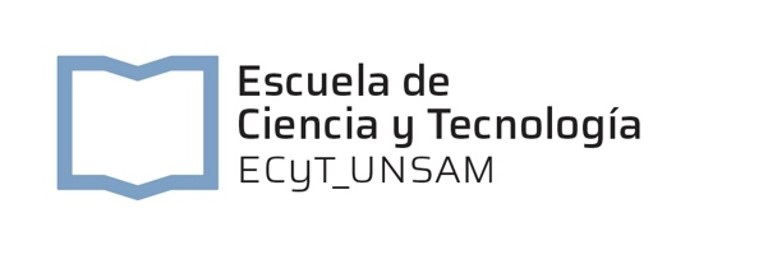

<div align="center">

<h1>MODELOS Y SISTEMAS</h1>

<h2>TRABAJO FINAL</h2>

<h1>Modelo de contaminante en reactor</h1>

<p><b>Autores:</b></p>
<p>Ballan, Nicole<br>Pantozzi, Jeremías<br>Ojeda, Augusto</p>

<p><b>Docentes:</b></p>
<p>Rubio Diana<br>Soria Paula Romina<br>La Mura Guillermo</p>

<p>Noviembre 2026</p>

</div>

---

|  |  |
| :--- | ---: |
| 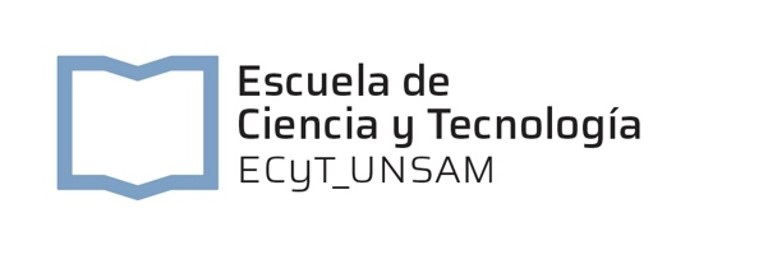<br>**Modelo de contaminante en reactor**<br>Ballan Nicole, Pantozzi Jeremías, Ojeda Augusto | Noviembre, 2026 |

---

<div align="center">
<p style="font-size:12pt">Modelo de contaminante en reactor</p>
<p style="font-size:11pt">Ballan Nicole; Pantozzi Jeremías; Ojeda Augusto</p>
<p style="font-size:10pt"><i>Escuela de Ciencia y Tecnología, Universidad Nacional de San Martín,<br>
25 de Mayo y Francia,1650 San Martín, Buenos Aires, Argentina<br>
<a href="mailto:correo@autor1.com">correo@autor1.com</a>,
<a href="mailto:correo@autor2.com">jmpantozzi@estudiantes.unsam.edu.ar</a>,
<a href="mailto:correo@autor3.com">agojeda@estudiantes.unsam.edu.ar</a></i></p>
</div>

**Resumen:** En el presente trabajo se estudia un modelo matemático utilizado para describir la biodegradación de contaminantes en recursos hídricos, fundamentado en el principio de conservación de la materia e incorporando una cinética saturable de tipo Michaelis-Menten. Mediante herramientas numéricas implementadas en Python, se analiza el sistema no lineal y su linealización alrededor de un punto de equilibrio, con el objetivo de determinar la evolución temporal de la concentración, la masa acumulada y la fuente contaminante. Se calculan los puntos de equilibrio, se evalúa su estabilidad mediante los autovalores de la matriz jacobiana y se comparan las simulaciones temporales de ambos modelos. Además, se obtiene la función de transferencia para estudiar la respuesta de la concentración frente a perturbaciones externas, incluyendo las respuestas al impulso y al escalón. Los resultados indican estabilidad matemática local del modelo, aunque ambos equilibrios presentan valores negativos en alguna variable, lo que limita su interpretación física.

Palabras claves: ***Contaminantes ambientales, Recursos hídricos, Biodegradación, Python, Linealización, Función de transferencia.***


## 1. Introducción

La incorporación de contaminantes a los sistemas acuáticos, como consecuencia de actividades humanas o eventos accidentales, constituye una problemática ambiental que puede afectar significativamente la calidad del agua. El estudio de los mecanismos de transporte, transformación y eliminación de estas sustancias resulta fundamental para comprender su comportamiento y predecir su evolución temporal. En este contexto, los modelos matemáticos permiten representar de manera simplificada los procesos involucrados y analizar la respuesta del sistema ante diferentes condiciones.

Para abordar esta problemática, se considera un reactor perfectamente mezclado de volumen constante, en el cual un contaminante es transportado mediante flujos de entrada y salida, eliminado a través de procesos de degradación biológica y aportado por una fuente variable en el tiempo. La formulación se fundamenta en el principio de conservación de la materia, aplicado al transporte de contaminantes en medios acuáticos, tomando como referencia los desarrollos de Fischer et al. (1979). Este principio se expresa mediante el siguiente balance general:

$$
\boxed{\text{Acumulación}=\text{Entrada}-\text{Salida}+\text{Generación}-\text{Eliminación}}
\tag{1}
$$

Considerando una concentración uniforme en el reactor, la masa disuelta del contaminante puede expresarse como $m_C=VC$, donde $V$ representa el volumen del reactor y $C$ la concentración. Si inicialmente se supone una eliminación de primer orden, caracterizada por una constante $k$, el balance de materia adopta la forma:

$$
\frac{d(VC)}{dt}=QC_{\mathrm{in}}-QC+VS-kVC
\tag{2}
$$

donde $Q$ representa el caudal volumétrico, $C_{\mathrm{in}}$ la concentración del flujo de entrada y $S$ una fuente interna de contaminante por unidad de volumen.

Sin embargo, la hipótesis de eliminación de primer orden supone que la velocidad de degradación aumenta proporcionalmente con la concentración, comportamiento que puede resultar insuficiente cuando la eliminación depende de microorganismos cuya capacidad de degradación es limitada. Por este motivo, se adopta una cinética saturable de tipo Michaelis-Menten, utilizada para describir procesos de biodegradación [1, 2]:

$$
r_d(C)=\frac{K_{\max}C}{K_m+C}
\tag{3}
$$

En esta expresión, $K_{\max}$ representa la velocidad máxima de degradación por unidad de volumen y $K_m$ la constante de semisaturación. Para concentraciones considerablemente menores que $K_m$, la expresión puede aproximarse mediante una cinética de primer orden, estableciendo la relación $K_{\max}=kK_m$. De esta manera, se reemplaza el término de eliminación lineal por una formulación no lineal que contempla la saturación del proceso biológico.

A partir de estas consideraciones, el comportamiento dinámico del reactor se describe mediante tres variables de estado: la concentración del contaminante $C(t)$, la masa acumulada $M(t)$ y la intensidad de la fuente contaminante $S(t)$. El sistema de ecuaciones diferenciales propuesto es:

$$
\begin{aligned}
\dot C &= -\frac{Q}{V}C-\frac{K_{\max}C}{K_m+C}+S\\[6pt]
\dot M &= Q(C_{\mathrm{in}}-C)-k_rM\\[6pt]
\dot S &= -\lambda S+u(t)
\end{aligned}
\tag{4}
$$

* La primera ecuación describe la evolución de la concentración considerando la salida del contaminante, su degradación biológica y el aporte de la fuente interna.

* La segunda representa la evolución de la variable de masa acumulada, incluyendo los intercambios asociados al caudal y un término de eliminación de primer orden.

* La tercera ecuación caracteriza el decaimiento de la fuente contaminante mediante la constante $\lambda$, incorporando una entrada externa $u(t)$ que permite representar aportes adicionales o perturbaciones sobre el sistema.

A partir del modelo propuesto, se busca caracterizar su comportamiento dinámico mediante la determinación de los puntos de equilibrio y el análisis de su estabilidad. Para ello, se realizarán simulaciones numéricas bajo diferentes condiciones iniciales y se obtendrá un modelo linealizado alrededor de un punto de equilibrio. Finalmente, se compararán las respuestas temporales y los diagramas de fase de ambos modelos, y se estudiará su respuesta ante perturbaciones externas mediante el análisis de la función de transferencia.


## 2. Materiales y Métodos

Para el análisis del comportamiento dinámico del sistema se utilizó el lenguaje de programación **Python**, trabajando en el entorno **Jupyter Notebook**, que permite integrar desarrollos matemáticos, cálculos numéricos y representaciones gráficas. La implementación computacional se realizó mediante las siguientes bibliotecas:

- **NumPy:** se utilizó para el manejo de vectores y matrices, el cálculo de autovalores, la manipulación de polinomios y la generación de arreglos numéricos necesarios para las simulaciones.

- **SciPy:** permitió implementar diferentes herramientas de análisis numérico. Se empleó `scipy.optimize.root` para determinar los puntos de equilibrio del sistema, `scipy.integrate.solve_ivp` para resolver numéricamente las ecuaciones diferenciales y `scipy.signal` para obtener la función de transferencia y calcular las respuestas al impulso y al escalón.

- **Matplotlib:** se utilizó para representar gráficamente las soluciones temporales, los diagramas de fase bidimensionales y tridimensionales, los polos y ceros de la función de transferencia y las respuestas dinámicas del sistema. Adicionalmente, se empleó `inset_axes` para ampliar regiones de interés en las representaciones gráficas.

A partir de estas herramientas se desarrolló el análisis del modelo no lineal y su posterior linealización, estudiando los puntos de equilibrio, la estabilidad y la evolución temporal del sistema frente a distintas condiciones iniciales. Los procedimientos empleados se describen a continuación.



### 2.1. Parámetros y condiciones de simulación

Para el estudio del modelo no lineal presentado en la ecuación (4), se adoptaron los parámetros y condiciones iniciales que se detallan a continuación. La formulación se fundamenta en los principios de transporte y conservación de materia desarrollados por Fischer et al. (1979), mientras que los trabajos de Shetty y Shetty (2016) [1] y Lv et al. (2022) [2] se tomaron como antecedentes para la descripción de los procesos de biodegradación.

Los valores utilizados permiten caracterizar el comportamiento dinámico del reactor y realizar las simulaciones numéricas correspondientes.

**Condiciones iniciales:**

$$
C(0)=0.5\ \mathrm{mg\,L^{-1}}, \qquad
M(0)=1\ \mathrm{mg}, \qquad
S(0)=0.5\ \mathrm{mg\,L^{-1}\,min^{-1}}
$$

**Tabla 1. Parámetros utilizados en el modelo.**

| Parámetro | Valor | Unidad | Descripción |
| :---: | :---: | :---: | :--- |
| $Q$ | 1 | $\mathrm{L\,min^{-1}}$ | Caudal de entrada y salida |
| $V$ | 10 | $\mathrm{L}$ | Volumen del reactor |
| $C_{\mathrm{in}}$ | 1 | $\mathrm{mg\,L^{-1}}$ | Concentración de entrada |
| $K_{\max}$ | 0.644 | $\mathrm{mg\,L^{-1}\,min^{-1}}$ | Velocidad máxima de degradación biológica |
| $K_m$ | 12.88 | $\mathrm{mg\,L^{-1}}$ | Constante de semisaturación |
| $k_r$ | 0.02 | $\mathrm{min^{-1}}$ | Constante de remoción de masa |
| $\lambda$ | 0.1 | $\mathrm{min^{-1}}$ | Constante de decaimiento de la fuente |

Para la resolución numérica del sistema se consideró un intervalo temporal de $0$ a $100$ minutos, seleccionando $N=5000$ instantes de evaluación equiespaciados. Asimismo, se adoptó una entrada externa constante $u(t)$, con el propósito de estudiar el comportamiento del reactor bajo un aporte sostenido a la fuente contaminante.

**Condiciones de simulación:**

$$
t\in[0,100]\ \mathrm{min}, \qquad N=5000
$$

$$
u(t)=0.2\ \mathrm{mg\,L^{-1}\,min^{-2}}
$$



### 2.2. Puntos de equilibrio y sistema linealizado

#### Determinación de los puntos de equilibrio

Para determinar los puntos de equilibrio del modelo no lineal presentado en la ecuación (4), se igualaron a cero las tres ecuaciones diferenciales del sistema, considerando una entrada externa constante $u(t)=0.2$.

$$
\begin{aligned}
0 &= -\frac{Q}{V}C^*-\frac{K_{\max}C^*}{K_m+C^*}+S^*\\[4pt]
0 &= Q(C_{\mathrm{in}}-C^*)-k_rM^*\\[4pt]
0 &= -\lambda S^*+u(t)
\end{aligned}
\tag{5}
$$

Donde $C^*$, $M^*$ y $S^*$ representan los valores de las variables de estado en el equilibrio.

Despejando $S^*$ de la tercera ecuación y sustituyendo en la primera, se obtiene una expresión que puede reorganizarse como una ecuación cuadrática para la concentración de equilibrio:

$$
\frac{Q}{V}(C^*)^2+
\left(\frac{QK_m}{V}+K_{\max}-S^*\right)C^*
-S^*K_m=0
\tag{6}
$$

Por lo tanto, para los parámetros considerados, el sistema presenta dos puntos de equilibrio matemáticos.

Para determinar numéricamente ambos puntos se utilizó la función `root` de la biblioteca `scipy.optimize`, que permite encontrar las raíces de un sistema de ecuaciones no lineales. Se emplearon dos estimaciones iniciales diferentes, con el objetivo de obtener ambas soluciones.

#### Linealización del sistema

Para estudiar el comportamiento del sistema en las proximidades de un punto de equilibrio, se realizó una linealización mediante una aproximación de Taylor de primer orden.

Considerando el vector de estado $\mathbf{x}=[C,M,S]^T$, el sistema linealizado alrededor de un punto de equilibrio $\mathbf{x}^*$, para una entrada externa constante, se expresa como:

$$
\dot{\mathbf{x}}=A(\mathbf{x}-\mathbf{x}^*) + u(t)
\tag{7}
$$

Donde $A$ es la matriz jacobiana del sistema no lineal evaluada en el punto de equilibrio seleccionado.

La matriz jacobiana se obtiene calculando las derivadas parciales de cada ecuación diferencial respecto de las variables de estado:

$$
J(C,M,S)=
\begin{pmatrix}
-\dfrac{Q}{V}-\dfrac{K_{\max}K_m}{(K_m+C)^2} & 0 & 1\\[8pt]
-Q & -k_r & 0\\[4pt]
0 & 0 & -\lambda
\end{pmatrix}
\tag{8}
$$

Para realizar la linealización se seleccionó el primer punto de equilibrio obtenido numéricamente:

$$
\mathbf{x}^*=
\begin{pmatrix}
16.39352\\
-769.67615\\
2
\end{pmatrix}
$$

Evaluando la matriz jacobiana en este punto, se obtiene:

$$
A=J(\mathbf{x}^*)=
\begin{pmatrix}
-0.10967947 & 0 & 1\\
-1 & -0.02 & 0\\
0 & 0 & -0.1
\end{pmatrix}
\tag{9}
$$

Finalmente, sustituyendo la matriz $A$ y los valores del equilibrio en la ecuación (7), se obtiene el sistema linealizado:

$$
\begin{aligned}
\dot C &= -0.10968(C-16.39352)+(S-2)\\[4pt]
\dot M &= -(C-16.39352)-0.02(M+769.67615)\\[4pt]
\dot S &= -0.1(S-2) + u(t)
\end{aligned}
\tag{10}
$$

Este sistema permite aproximar el comportamiento del modelo no lineal en las proximidades del punto de equilibrio seleccionado. Para analizar su estabilidad local, se calcularon los autovalores de la matriz jacobiana $A$ mediante la función `numpy.linalg.eigvals`.

### 2.3. Función de transferencia

Para analizar la respuesta dinámica del sistema ante perturbaciones externas, se determinó la función de transferencia del modelo linealizado. Se consideró como entrada la variación de la fuente externa $u(t)$ y como salida la concentración del contaminante $C(t)$, debido al interés en estudiar cómo los cambios en el aporte de contaminantes afectan su concentración dentro del reactor.

Para obtener la función de transferencia se aplica la transformada de Laplace al sistema linealizado, considerando condiciones iniciales nulas para las variables de perturbación. La relación entre la entrada y la salida queda definida por:

$$
H(s)=\frac{\Delta C(s)}{\Delta U(s)}
\tag{12}
$$

A partir de las ecuaciones correspondientes a $C$ y $S$, se obtiene:

$$
\begin{aligned}
s\Delta C(s)&=-a\Delta C(s)+\Delta S(s)\\
s\Delta S(s)&=-\lambda\Delta S(s)+\Delta U(s)
\end{aligned}
$$

donde $a=-A_{11}=0.10967947$ y $\lambda=-A_{33}=0.1$. Despejando y combinando ambas expresiones, se obtiene la función de transferencia:

$$
\boxed{
H(s)=\frac{1}{(s+a)(s+\lambda)}
=\frac{1}{s^2+0.20967947s+0.01096795}
}
\tag{13}
$$

Para su implementación numérica en Python, se utilizaron los coeficientes de la matriz jacobiana evaluada. El numerador se definió mediante el elemento $A_{13}$, mientras que el denominador se construyó multiplicando los polinomios $(s+a)$ y $(s+\lambda)$ mediante la función `numpy.polymul`.

Posteriormente, se empleó la función `numpy.roots` para calcular las raíces de los polinomios del numerador y denominador, correspondientes a los ceros y polos de la función de transferencia, respectivamente.

Finalmente, mediante las funciones `TransferFunction`, `impulse` y `step` de la biblioteca `scipy.signal`, se construyó la representación del sistema y se calcularon sus respuestas temporales ante entradas de tipo impulso y escalón, con el objetivo de caracterizar su comportamiento dinámico frente a perturbaciones externas.

## 3. Experimentos numéricos

Con las funciones `Root` se llego a los puntos de equilibrio, a partir de los mismos se realizaron las simulaciones temporales de fase y de respuesta temporal, asi como la linealizacion al rededor del punto P.E. 1 

In [3]:
#Librerias a usar 

import numpy as np
import matplotlib.pyplot as plt 
from scipy.integrate import solve_ivp
from scipy.optimize import root
from scipy.signal import TransferFunction, impulse, step
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ====================================
# ======  Definicion de modelos ======
# ====================================

#CTES
Q= 1 #L min^-1
Cin= 1 #mgL^-1
kr= 0.02 #min^-1
V= 10 #L
K=0.05 #min^-1
Lamda=0.1 #min^-1
Km=12.88 #mg L^-1
Kmax=K * Km #mg L^-1 min^-1
    

#Condiciones iniciales
C_0=0.5 #mg L^-1
M_0=1 #mg
S_0=0.5 #mg L^-1 min^-1
C_iniciales=[C_0,M_0,S_0]
C_inicialesbis=[30,500,10]
C_inicialesbis2=[150,1000,25]
C_Inicialeseq2_0=[40, 700, 1]
C_Inicialeseq2_1=[150, 1500, 0]
C_Inicialeseq2_2=[10, 10, 18]
u=0.2 #mg min^-2


def modelo(t,y):
    C,M,S=y #defino C M y S como vector dependiente del tiempo
    C_der=-(Q/V)*C-(Kmax*C/(Km+C))+S
    M_der=Q*(Cin-C)-kr*M
    S_der=-Lamda*S+u
    return[C_der,M_der,S_der]

def jacobiano_Modelo(y):
   C,M,S=y
   A=np.array([[-Q/V-(Kmax*Km)/(Km+C)**2,0,1],
              [-Q, -kr, 0],
              [0, 0, -Lamda]])
   return A

def modelo_linealizado(t,y,A,X_eq):
    X_linealizado=A@(y-X_eq)
    return X_linealizado

# ====================================
# ======  Puntos de Equilibrio  ======
# ====================================
Solucion_1 = root(lambda y: modelo(0, y), C_iniciales) #Root me pide que le un punto para arrancar. por eso meto C iniciales y escribo lambda y: modelo(0, y) asi entiende que quiere variar y obtener valores de M C Y S 
Solucion_2 = root(lambda y: modelo(0, y), [-16, 800, 2])
X_eq = Solucion_1.x
print("=== PUNTOS DE EQUILIBRIO ===")
print("P.E. 1:", Solucion_1.x)
print("P.E. 2:", Solucion_2.x)

=== PUNTOS DE EQUILIBRIO ===
P.E. 1: [  16.39352298 -769.67614889    2.        ]
P.E. 2: [-15.71352298 835.67614889   2.        ]


In [10]:
# ====================================
# ======  Analisis temporales  =======
# ====================================

#Variables de simulacion
N=5000
t_max=100
t=np.linspace(0,t_max, N)

#Aplico ode para el primer punto de equilibrio
sol = solve_ivp(modelo, (0, t_max), C_iniciales, t_eval=t) 
sol2 = solve_ivp(modelo, (0, t_max), C_inicialesbis, t_eval=t)
sol3 = solve_ivp(modelo, (0, t_max), C_inicialesbis2, t_eval=t)
#Aplico ode para el primer punto de equilibrio
sol4= solve_ivp(modelo, (0, t_max), C_Inicialeseq2_0, t_eval=t)
sol5= solve_ivp(modelo, (0, t_max), C_Inicialeseq2_1, t_eval=t)
sol6= solve_ivp(modelo, (0, t_max), C_Inicialeseq2_2, t_eval=t)

# ==============================
# ======  Linealizacion  =======
# ==============================

#Evaluo el jacobiano en el punto de equlibrio
A1=jacobiano_Modelo(X_eq)
print("Jacobiano evaluado en el punto")
print(A1)

print("\n=== ECUACIONES LINEALIZADAS ===")

print(f"C_der = {A1[0,0]:.5f}*(C - ({X_eq[0]:.5f})) + (S - ({X_eq[2]:.5f}))")

print(f"M_der = {A1[1,0]:.5f}*(C - ({X_eq[0]:.5f})) + {A1[1,1]:.5f}*(M - ({X_eq[1]:.5f}))")

print(f"S_der = {A1[2,2]:.5f}*(S - ({X_eq[2]:.5f}))")

#Calculo de autovalores
autovalores=np.linalg.eigvals(A1)
print("\n=== Calculo de autovalores ===")
print(f"λ1 = {autovalores[0]}, λ2 = {autovalores[1]}, λ3 = {autovalores[2]}")

#Analizis del punto 1 para modelo linealizado. 
# Condición inicial del enunciado
sol1_lin = solve_ivp(modelo_linealizado, (0, t_max),
                     C_iniciales, t_eval=t, args=(A1, X_eq))
# Condiciones iniciales alternativas
sol2_lin = solve_ivp(modelo_linealizado, (0, t_max),
                     C_inicialesbis, t_eval=t, args=(A1, X_eq))
sol3_lin = solve_ivp(modelo_linealizado, (0, t_max),
                     C_inicialesbis2, t_eval=t, args=(A1, X_eq))



Jacobiano evaluado en el punto
[[-0.10967947  0.          1.        ]
 [-1.         -0.02        0.        ]
 [ 0.          0.         -0.1       ]]

=== ECUACIONES LINEALIZADAS ===
C_der = -0.10968*(C - (16.39352)) + (S - (2.00000))
M_der = -1.00000*(C - (16.39352)) + -0.02000*(M - (-769.67615))
S_der = -0.10000*(S - (2.00000))

=== Calculo de autovalores ===
λ1 = -0.02, λ2 = -0.10967947376878395, λ3 = -0.1


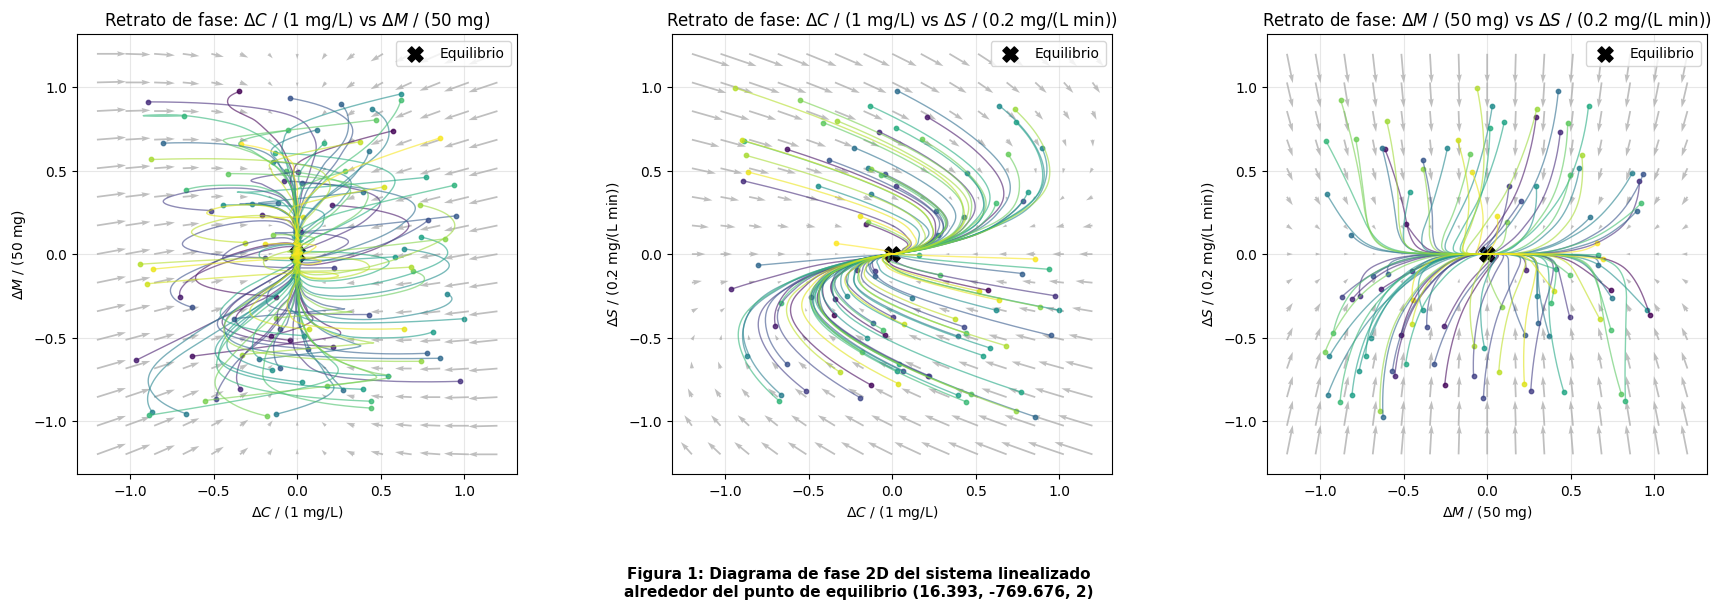

In [11]:
#===========================================
#======= Autovalores Linealizado ===========
#===========================================

# Tiempo de simulación
t_fase = np.linspace(0, 300, 1000)

# Escalas para normalizar las variables
escalas = np.array([1, 50, 0.2])

# Generamos muchas perturbaciones iniciales
rng = np.random.default_rng(8)
N_trayectorias = 100
perturbaciones = rng.uniform(-1, 1, size=(N_trayectorias, 3)) * escalas

# Colores para las trayectorias
colores = plt.cm.viridis(np.linspace(0, 1, N_trayectorias))

# Creamos figura con 3 subgráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Pares de variables a proyectar
# (indice_x, indice_y, nombre_x, nombre_y)
proyecciones = [
    (0, 1, r'$\Delta C$ / (1 mg/L)', r'$\Delta M$ / (50 mg)'),
    (0, 2, r'$\Delta C$ / (1 mg/L)', r'$\Delta S$ / (0.2 mg/(L min))'),
    (1, 2, r'$\Delta M$ / (50 mg)', r'$\Delta S$ / (0.2 mg/(L min))')
]


# Campo de direcciones 2D

grid_vals = np.linspace(-1.2, 1.2, 15)

for ax, (ix, iy, xlabel, ylabel) in zip(axes, proyecciones):

    # Malla para el campo
    Xg, Yg = np.meshgrid(grid_vals, grid_vals)

    Ug = np.zeros_like(Xg)
    Vg = np.zeros_like(Yg)

    # Construimos el campo a partir del modelo linealizado
    for m in range(Xg.shape[0]):
        for n in range(Xg.shape[1]):

            # Estado desplazado normalizado -> lo llevamos a unidades reales
            delta = np.zeros(3)
            delta[ix] = Xg[m, n] * escalas[ix]
            delta[iy] = Yg[m, n] * escalas[iy]

            # En el sistema linealizado: dX = A1 @ delta
            dX = A1 @ delta

            # Normalizamos la derivada en los ejes elegidos
            Ug[m, n] = dX[ix] / escalas[ix]
            Vg[m, n] = dX[iy] / escalas[iy]

    # Dibujamos campo de direcciones
    ax.quiver(Xg, Yg, Ug, Vg, color='gray', alpha=0.5)

# Trayectorias

    for i, perturbacion in enumerate(perturbaciones):

        # Condición inicial cerca del equilibrio
        X0 = X_eq + perturbacion

        # Resolvemos el sistema linealizado
        sol_lin = solve_ivp(
            modelo_linealizado,
            (0, 300),
            X0,
            t_eval=t_fase,
            args=(A1, X_eq)
        )

        # Variables desplazadas y normalizadas
        Z = (sol_lin.y - X_eq[:, None]) / escalas[:, None]

        # Dibujamos la proyección 2D
        ax.plot(
            Z[ix], Z[iy],
            color=colores[i],
            linewidth=1,
            alpha=0.6
        )

        # Marcamos el punto inicial
        ax.scatter(
            Z[ix, 0], Z[iy, 0],
            color=colores[i],
            s=10,
            alpha=0.8
        )

    # Punto de equilibrio
    ax.scatter(
        0, 0,
        color='black',
        marker='X',
        s=120,
        label='Equilibrio'
    )

    ax.set_title(f'Retrato de fase: {xlabel} vs {ylabel}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal', adjustable='box')
    ax.legend()
# Reservamos espacio debajo de los tres gráficos
plt.tight_layout(rect=[0, 0.18, 1, 1])

# Pie de figura centrado
fig.text(
    0.5, 0.06,
    'Figura 1: Diagrama de fase 2D del sistema linealizado\n'
    'alrededor del punto de equilibrio (16.393, -769.676, 2)',
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold'
)

plt.show()

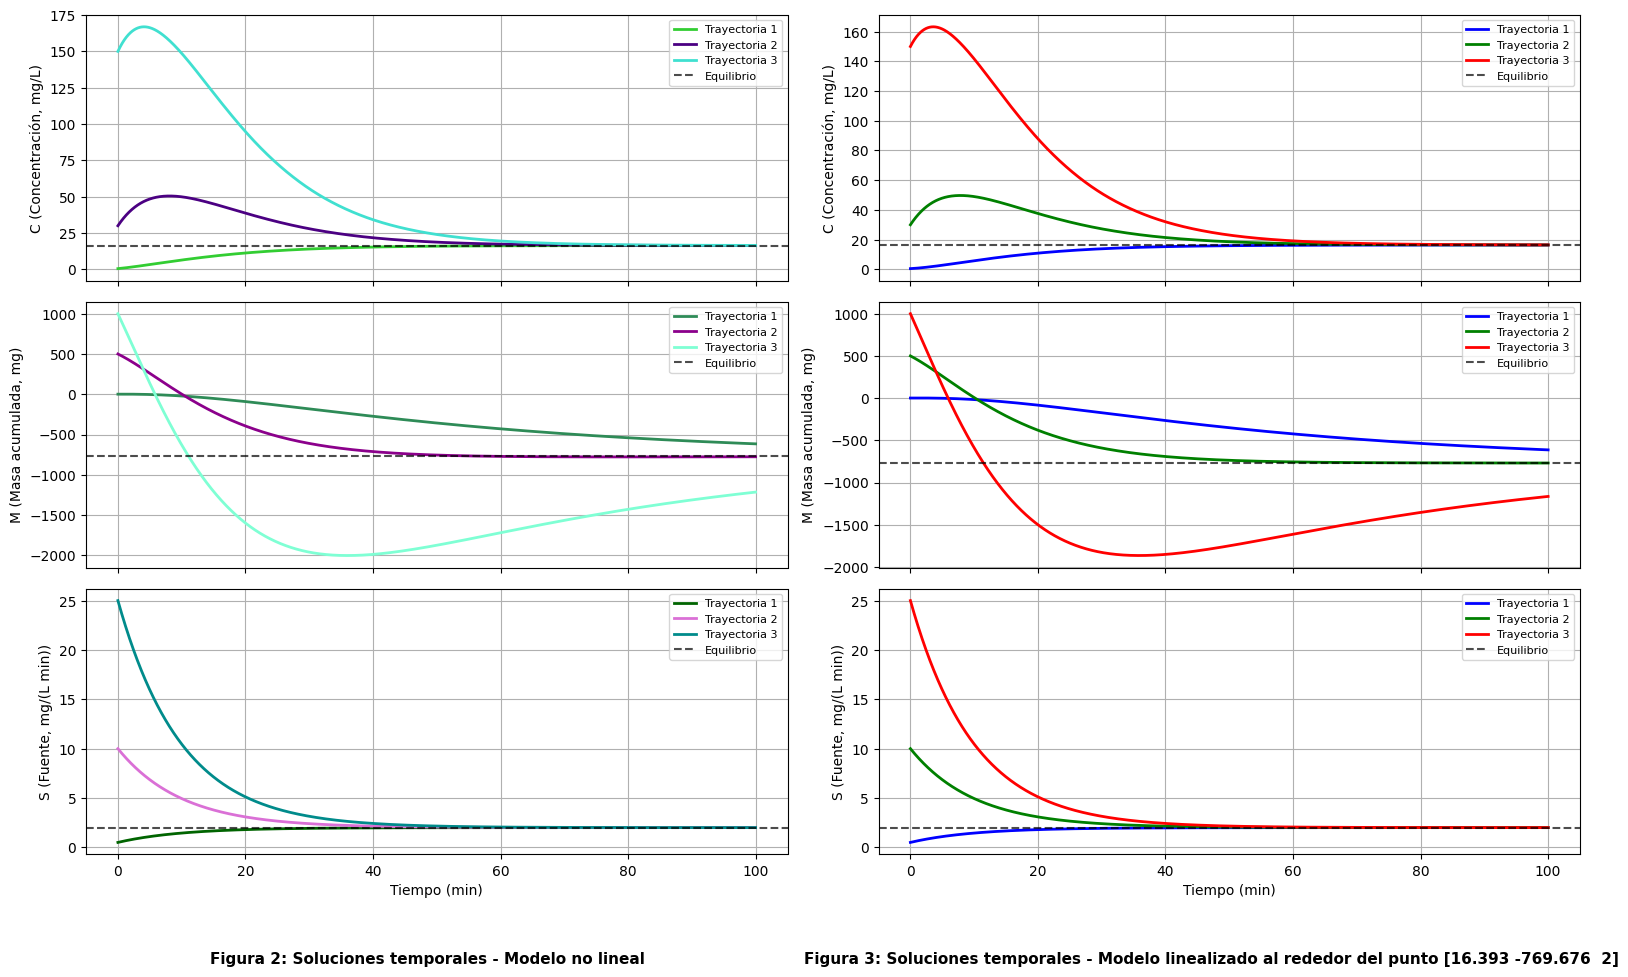

In [12]:
# ==========================================
# COMPARACIÓN DE SOLUCIONES TEMPORALES
# Modelo no lineal vs modelo linealizado
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex='col')

# ------------------------------
# COLUMNA IZQUIERDA: NO LINEAL
# ------------------------------

# C(t)
axes[0, 0].plot(sol.t,  sol.y[0],  label='Trayectoria 1', color='limegreen', linewidth=2)
axes[0, 0].plot(sol2.t, sol2.y[0], label='Trayectoria 2', color='indigo', linewidth=2)
axes[0, 0].plot(sol3.t, sol3.y[0], label='Trayectoria 3', color='turquoise', linewidth=2)
axes[0, 0].axhline(Solucion_1.x[0], color='k', linestyle='--', alpha=0.7, label='Equilibrio')
axes[0, 0].set_ylabel('C (Concentración, mg/L)')
axes[0, 0].grid(True)
axes[0, 0].legend(fontsize=8)

# M(t)
axes[1, 0].plot(sol.t,  sol.y[1],  label='Trayectoria 1', color='seagreen', linewidth=2)
axes[1, 0].plot(sol2.t, sol2.y[1], label='Trayectoria 2', color='darkmagenta', linewidth=2)
axes[1, 0].plot(sol3.t, sol3.y[1], label='Trayectoria 3', color='aquamarine', linewidth=2)
axes[1, 0].axhline(Solucion_1.x[1], color='k', linestyle='--', alpha=0.7, label='Equilibrio')
axes[1, 0].set_ylabel('M (Masa acumulada, mg)')
axes[1, 0].grid(True)
axes[1, 0].legend(fontsize=8)

# S(t)
axes[2, 0].plot(sol.t,  sol.y[2],  label='Trayectoria 1', color='darkgreen', linewidth=2)
axes[2, 0].plot(sol2.t, sol2.y[2], label='Trayectoria 2', color='orchid', linewidth=2)
axes[2, 0].plot(sol3.t, sol3.y[2], label='Trayectoria 3', color='darkcyan', linewidth=2)
axes[2, 0].axhline(Solucion_1.x[2], color='k', linestyle='--', alpha=0.7, label='Equilibrio')
axes[2, 0].set_xlabel('Tiempo (min)')
axes[2, 0].set_ylabel('S (Fuente, mg/(L min))')
axes[2, 0].grid(True)
axes[2, 0].legend(fontsize=8)

# ------------------------------
# COLUMNA DERECHA: LINEALIZADO
# ------------------------------

# C(t)
axes[0, 1].plot(t, sol1_lin.y[0], label='Trayectoria 1', color='b', linewidth=2)
axes[0, 1].plot(t, sol2_lin.y[0], label='Trayectoria 2', color='g', linewidth=2)
axes[0, 1].plot(t, sol3_lin.y[0], label='Trayectoria 3', color='r', linewidth=2)
axes[0, 1].axhline(X_eq[0], color='k', linestyle='--', alpha=0.7, label='Equilibrio')
axes[0, 1].set_ylabel('C (Concentración, mg/L)')
axes[0, 1].grid(True)
axes[0, 1].legend(fontsize=8)

# M(t)
axes[1, 1].plot(t, sol1_lin.y[1], label='Trayectoria 1', color='b', linewidth=2)
axes[1, 1].plot(t, sol2_lin.y[1], label='Trayectoria 2', color='g', linewidth=2)
axes[1, 1].plot(t, sol3_lin.y[1], label='Trayectoria 3', color='r', linewidth=2)
axes[1, 1].axhline(X_eq[1], color='k', linestyle='--', alpha=0.7, label='Equilibrio')
axes[1, 1].set_ylabel('M (Masa acumulada, mg)')
axes[1, 1].grid(True)
axes[1, 1].legend(fontsize=8)

# S(t)
axes[2, 1].plot(t, sol1_lin.y[2], label='Trayectoria 1', color='b', linewidth=2)
axes[2, 1].plot(t, sol2_lin.y[2], label='Trayectoria 2', color='g', linewidth=2)
axes[2, 1].plot(t, sol3_lin.y[2], label='Trayectoria 3', color='r', linewidth=2)
axes[2, 1].axhline(X_eq[2], color='k', linestyle='--', alpha=0.7, label='Equilibrio')
axes[2, 1].set_xlabel('Tiempo (min)')
axes[2, 1].set_ylabel('S (Fuente, mg/(L min))')
axes[2, 1].grid(True)
axes[2, 1].legend(fontsize=8)

plt.tight_layout()
fig.subplots_adjust(bottom=0.14)

# Título debajo de la columna izquierda
fig.text(
    0.27, 0.035,
    'Figura 2: Soluciones temporales - Modelo no lineal',
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold'
)

# Título debajo de la columna derecha
fig.text(
    0.76, 0.035,
    'Figura 3: Soluciones temporales - Modelo linealizado al rededor del punto [16.393 -769.676  2]',
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold'
)

plt.show()


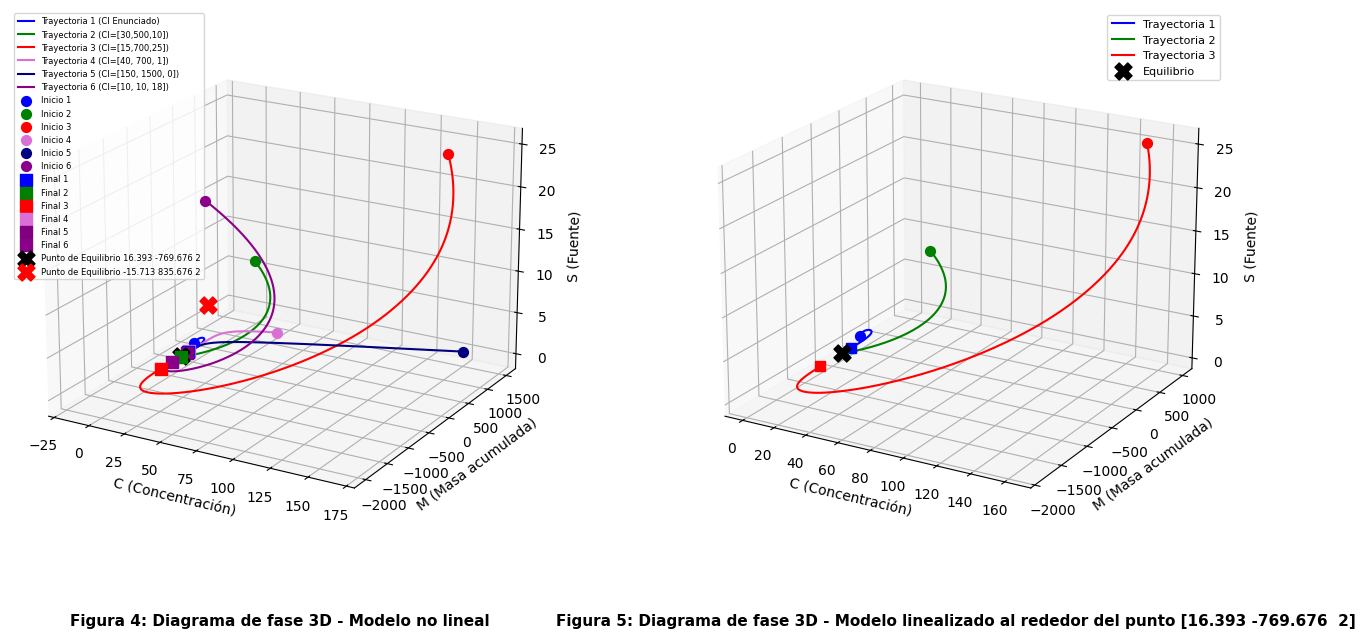

In [13]:
# ==========================================
# COMPARACIÓN DE DIAGRAMAS DE FASE 3D
# Modelo no lineal vs modelo linealizado
# ==========================================

fig = plt.figure(figsize=(16, 7))

ax1 = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122, projection='3d')


# ------------------------------
# IZQUIERDA: MODELO NO LINEAL
# ------------------------------

# Trayectorias del sistema
ax1.plot(sol.y[0], sol.y[1], sol.y[2], color='b',
         label='Trayectoria 1 (CI Enunciado)')

ax1.plot(sol2.y[0], sol2.y[1], sol2.y[2], color='g',
         label='Trayectoria 2 (CI=[30,500,10])')

ax1.plot(sol3.y[0], sol3.y[1], sol3.y[2], color='r',
         label='Trayectoria 3 (CI=[15,700,25])')

ax1.plot(sol4.y[0], sol4.y[1], sol4.y[2], color='orchid',
         label='Trayectoria 4 (CI=[40, 700, 1])')

ax1.plot(sol5.y[0], sol5.y[1], sol5.y[2], color='navy',
         label='Trayectoria 5 (CI=[150, 1500, 0])')

ax1.plot(sol6.y[0], sol6.y[1], sol6.y[2], color='darkmagenta',
         label='Trayectoria 6 (CI=[10, 10, 18])')


# ------------------------------
# Puntos iniciales
# ------------------------------

ax1.scatter(C_iniciales[0], C_iniciales[1], C_iniciales[2],
            color='b', marker='o', s=50, label='Inicio 1')

ax1.scatter(C_inicialesbis[0], C_inicialesbis[1], C_inicialesbis[2],
            color='g', marker='o', s=50, label='Inicio 2')

ax1.scatter(C_inicialesbis2[0], C_inicialesbis2[1], C_inicialesbis2[2],
            color='r', marker='o', s=50, label='Inicio 3')

ax1.scatter(C_Inicialeseq2_0[0], C_Inicialeseq2_0[1], C_Inicialeseq2_0[2],
            color='orchid', marker='o', s=50, label='Inicio 4')

ax1.scatter(C_Inicialeseq2_1[0], C_Inicialeseq2_1[1], C_Inicialeseq2_1[2],
            color='navy', marker='o', s=50, label='Inicio 5')

ax1.scatter(C_Inicialeseq2_2[0], C_Inicialeseq2_2[1], C_Inicialeseq2_2[2],
            color='darkmagenta', marker='o', s=50, label='Inicio 6')


# ------------------------------
# Puntos finales de las trayectorias
# ------------------------------

ax1.scatter(sol.y[0, -1], sol.y[1, -1], sol.y[2, -1],
            color='b', marker='s', s=70, label='Final 1')

ax1.scatter(sol2.y[0, -1], sol2.y[1, -1], sol2.y[2, -1],
            color='g', marker='s', s=70, label='Final 2')

ax1.scatter(sol3.y[0, -1], sol3.y[1, -1], sol3.y[2, -1],
            color='r', marker='s', s=70, label='Final 3')

ax1.scatter(sol4.y[0, -1], sol4.y[1, -1], sol4.y[2, -1],
            color='orchid', marker='s', s=70, label='Final 4')

ax1.scatter(sol5.y[0, -1], sol5.y[1, -1], sol5.y[2, -1],
            color='purple', marker='s', s=70, label='Final 5')

ax1.scatter(sol6.y[0, -1], sol6.y[1, -1], sol6.y[2, -1],
            color='darkmagenta', marker='s', s=70, label='Final 6')


# ------------------------------
# Puntos de equilibrio
# ------------------------------

ax1.scatter(Solucion_1.x[0], Solucion_1.x[1], Solucion_1.x[2],
            color='k', marker='X', s=150,
            label='Punto de Equilibrio 16.393 -769.676 2')

ax1.scatter(Solucion_2.x[0], Solucion_2.x[1], Solucion_2.x[2],
            color='r', marker='X', s=150,
            label='Punto de Equilibrio -15.713 835.676 2')


# ------------------------------
# Configuración del gráfico
# ------------------------------

ax1.text2D(
    0.5, -0.12,
    'Figura 4: Diagrama de fase 3D - Modelo no lineal',
    transform=ax1.transAxes,
    ha='center',
    va='top',
    fontsize=11,
    fontweight='bold'
)

ax1.set_xlabel('C (Concentración)')
ax1.set_ylabel('M (Masa acumulada)')
ax1.set_zlabel('S (Fuente)')
ax1.legend(fontsize=6)

# ------------------------------
# DERECHA: MODELO LINEALIZADO
# ------------------------------

ax2.plot(sol1_lin.y[0], sol1_lin.y[1], sol1_lin.y[2], color='b', label='Trayectoria 1')
ax2.plot(sol2_lin.y[0], sol2_lin.y[1], sol2_lin.y[2], color='g', label='Trayectoria 2')
ax2.plot(sol3_lin.y[0], sol3_lin.y[1], sol3_lin.y[2], color='r', label='Trayectoria 3')

# puntos iniciales
ax2.scatter(sol1_lin.y[0,0], sol1_lin.y[1,0], sol1_lin.y[2,0], color='b', marker='o', s=50)
ax2.scatter(sol2_lin.y[0,0], sol2_lin.y[1,0], sol2_lin.y[2,0], color='g', marker='o', s=50)
ax2.scatter(sol3_lin.y[0,0], sol3_lin.y[1,0], sol3_lin.y[2,0], color='r', marker='o', s=50)

# puntos finales
ax2.scatter(sol1_lin.y[0,-1], sol1_lin.y[1,-1], sol1_lin.y[2,-1], color='b', marker='s', s=60)
ax2.scatter(sol2_lin.y[0,-1], sol2_lin.y[1,-1], sol2_lin.y[2,-1], color='g', marker='s', s=60)
ax2.scatter(sol3_lin.y[0,-1], sol3_lin.y[1,-1], sol3_lin.y[2,-1], color='r', marker='s', s=60)

# equilibrio
ax2.scatter(X_eq[0], X_eq[1], X_eq[2],color='k', marker='X', s=150, label='Equilibrio')

ax2.text2D(
    0.5, -0.12,
    'Figura 5: Diagrama de fase 3D - Modelo linealizado al rededor del punto [16.393 -769.676  2]',
    transform=ax2.transAxes,
    ha='center',
    va='top',
    fontsize=11,
    fontweight='bold'
)

ax2.set_xlabel('C (Concentración)')
ax2.set_ylabel('M (Masa acumulada)')
ax2.set_zlabel('S (Fuente)')
ax2.legend(fontsize=8)

# misma vista en ambos
ax1.view_init(elev=20, azim=-60)
ax2.view_init(elev=20, azim=-60)


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
C:\Users\jerem\AppData\Local\Temp\ipykernel_12096\2671067970.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.



=== POLOS Y CEROS ===
Numerador: [1.]
Denominador: [1.         0.20967947 0.01096795]
Polos: [-0.10967947 -0.1       ]
Ceros: []


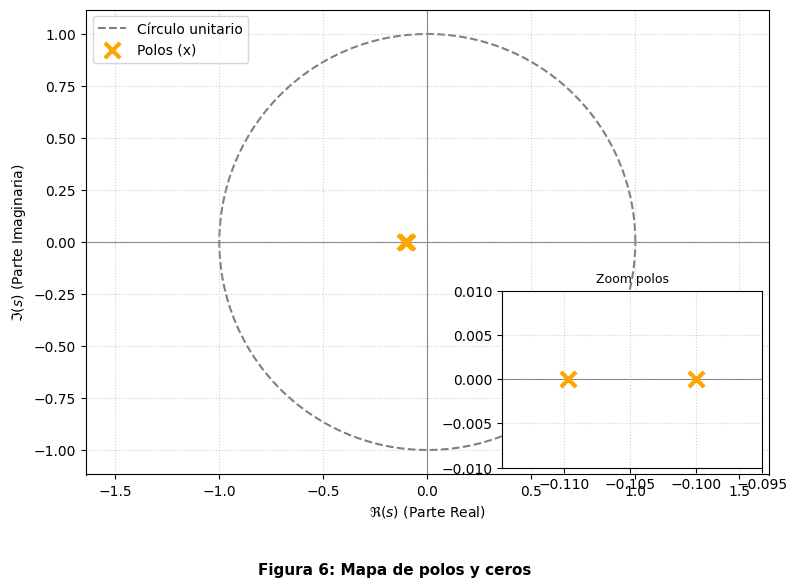

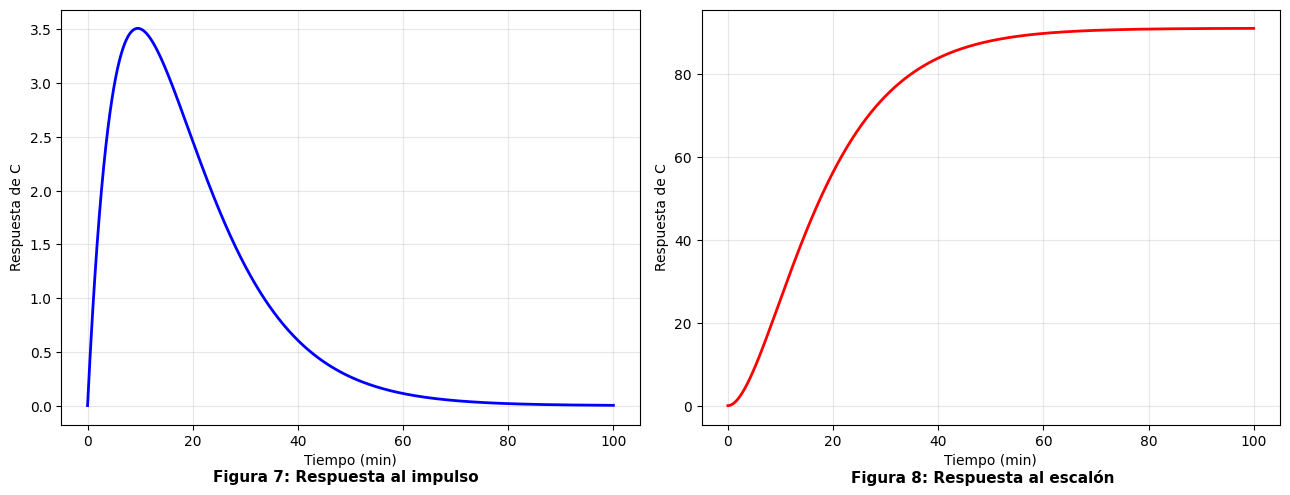

In [14]:
# ==========================================
# Polos y ceros de la función de transferencia
# ==========================================

# Coeficientes obtenidos del Jacobiano
a = -A1[0, 0]
lam = -A1[2, 2]
# Función de transferencia G(s) = num(s)/den(s)
numerador = np.array([A1[0, 2]])
# Multiplicamos (s+a)*(s+lam)
denominador = np.polymul([1, a], [1, lam])
# Calculamos las raíces
polos = np.roots(denominador)
ceros = np.roots(numerador)
print("\n=== POLOS Y CEROS ===")
print("Numerador:", numerador)
print("Denominador:", denominador)
print("Polos:", polos)
print("Ceros:", ceros)
# ==========================================
# Mapa de Polos y Ceros (Plano S)
# con recuadro de zoom sobre los polos
# ==========================================
fig2, ax3 = plt.subplots(figsize=(8, 6))
# Dibujamos el círculo unitario punteado al fondo (zorder=1)
theta = np.linspace(0, 2 * np.pi, 200)
ax3.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--',
         label='Círculo unitario', zorder=1)
# Dibujamos los ejes cartesianos al fondo (zorder=1)
ax3.axhline(0, color='gray', linewidth=0.8, zorder=1)
ax3.axvline(0, color='gray', linewidth=0.8, zorder=1)
# Graficamos los Ceros adelante (zorder=2)
if len(ceros) > 0:
    ax3.scatter(np.real(ceros), np.imag(ceros),
                s=80, facecolors='none',
                edgecolors='blue', linewidth=2,
                label='Ceros (o)', zorder=2)
# Graficamos los Polos al frente de todo (zorder=3)
if len(polos) > 0:
    ax3.scatter(np.real(polos), np.imag(polos),
                s=120, marker='x',
                color='orange', linewidth=3,
                label='Polos (x)', zorder=3)

ax3.set_xlabel(r'$\Re(s)$ (Parte Real)')
ax3.set_ylabel(r'$\Im(s)$ (Parte Imaginaria)')
ax3.grid(True, which='both', linestyle=':', alpha=0.6, zorder=1)
# Relación de aspecto 1:1 para que el círculo no se vea ovalado
ax3.axis('equal')
ax3.set_xlim([-1.5, 1.5])
ax3.set_ylim([-1.5, 1.5])
ax3.legend(loc='upper left')
# ==========================================
# Recuadro de zoom sobre los polos
# ==========================================
# Creamos un inset (recuadro pequeño)
axins = inset_axes(ax3, width="38%", height="38%", loc='lower right')
# Mismo contenido en el inset
axins.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--', zorder=1)
axins.axhline(0, color='gray', linewidth=0.8, zorder=1)
axins.axvline(0, color='gray', linewidth=0.8, zorder=1)
if len(ceros) > 0:
    axins.scatter(np.real(ceros), np.imag(ceros),
                  s=80, facecolors='none',
                  edgecolors='blue', linewidth=2, zorder=2)
if len(polos) > 0:
    axins.scatter(np.real(polos), np.imag(polos),
                  s=120, marker='x',
                  color='orange', linewidth=3, zorder=3)
# Elegimos la región de zoom alrededor de los polos
xmin = np.min(np.real(polos)) - 0.005
xmax = np.max(np.real(polos)) + 0.005
ymin = -0.01
ymax = 0.01
axins.set_xlim(xmin, xmax)
axins.set_ylim(ymin, ymax)
# Estética del recuadro
axins.grid(True, linestyle=':', alpha=0.6)
axins.set_title('Zoom polos', fontsize=9)

plt.tight_layout()
fig2.subplots_adjust(bottom=0.20)

# Título debajo de la figura
fig2.text(
    0.5, 0.04,
    'Figura 6: Mapa de polos y ceros',
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold'
)

plt.show()

# Respuesta al impulso y al escalon
G = TransferFunction(numerador, denominador)
# Calculamos la respuesta al impulso
t_impulso, y_impulso = impulse(G, T=t)
# Calculamos la respuesta al escalón
t_escalon, y_escalon = step(G, T=t)
# ==========================================
# Gráficas de las respuestas temporales
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Respuesta al impulso
axes[0].plot(
    t_impulso, y_impulso,
    color='blue',
    linewidth=2
)
axes[0].set_xlabel('Tiempo (min)')
axes[0].set_ylabel('Respuesta de C')
axes[0].grid(True, alpha=0.3)
# Respuesta al escalón
axes[1].plot(
    t_escalon, y_escalon,
    color='red',
    linewidth=2
)
axes[1].set_xlabel('Tiempo (min)')
axes[1].set_ylabel('Respuesta de C')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.subplots_adjust(bottom=0.14)

# Título debajo de la columna izquierda
fig.text(
    0.27, 0.035,
    'Figura 7: Respuesta al impulso',
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold'
)

# Título debajo de la columna derecha
fig.text(
    0.76, 0.035,
    'Figura 8: Respuesta al escalón',
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold'
)

plt.show()

## 4. Análisis y Discusión

#### 4.1. Sistema no linealizado

Los dos puntos de equilibrio obtenidos presentan limitaciones desde el punto de vista físico, dado que uno de ellos presenta una concentración negativa y el otro una masa acumulada negativa. Estas magnitudes representan cantidades físicas que deben satisfacer $C\geq 0$ y $M\geq 0$.

Por otra parte, en la Figura 2 se observa que las trayectorias simuladas a partir de condiciones iniciales físicamente posibles presentan una tendencia hacia el primer punto de equilibrio, $[C=16.393;\ M=-769.676;\ S=2]$.

Aunque dicho equilibrio no es completamente admisible físicamente debido al valor negativo de la masa, fue seleccionado para continuar con el análisis matemático del sistema, mientras que el segundo punto fue descartado por presentar una concentración negativa y por la tendencia del gráfico mencionado.

#### 4.2. Sistema linealizado

Al analizar los autovalores de la matriz jacobiana evaluada en el punto de equilibrio seleccionado, se observa que los tres son reales y negativos. Esto permite clasificar al equilibrio como un nodo asintóticamente estable.

Este comportamiento se representa en la Figura 1 mediante los retratos de fase bidimensionales del sistema linealizado. En ellos se observa cómo las trayectorias convergen hacia el origen de coordenadas, que corresponde al punto de equilibrio debido al desplazamiento y normalización de las variables de estado.


#### 4.3. Comparación de las soluciones temporales

En las Figuras 2 y 3 se presentan las soluciones temporales del modelo no lineal y del modelo linealizado, respectivamente.

Se observa que ambos modelos presentan un comportamiento dinámico similar, con trayectorias que tienden hacia el punto de equilibrio seleccionado. Este resultado es consistente con el análisis de estabilidad realizado previamente. Asimismo, en las Figuras 4 y 5 se representa este comportamiento mediante los diagramas de fase tridimensionales, considerando las variables de estado $C$, $M$ y $S$.

Sin embargo, las respuestas no son idénticas. Las principales diferencias se presentan durante el régimen transitorio, especialmente en los valores máximos alcanzados por la concentración $C(t)$ y en la evolución de la masa acumulada $M(t)$. Para condiciones iniciales iguales, estas diferencias se deben a que el modelo linealizado constituye una aproximación de primer orden del sistema original, cuya precisión es mayor en las proximidades del punto de equilibrio.

Por otra parte, la variable $S(t)$ presenta un comportamiento coincidente en ambos modelos cuando se consideran las mismas condiciones iniciales, debido a que su ecuación diferencial ya es lineal y no se modifica mediante el proceso de linealización.

Finalmente, se observa que la concentración y la fuente contaminante se aproximan a sus respectivos valores de equilibrio dentro del intervalo simulado, mientras que la masa acumulada presenta una evolución más lenta. Esto es consistente con el autovalor $\lambda_1=-0.02$, asociado a una dinámica de mayor escala temporal.

#### 4.4. Analisís de Función Transferencia

En la Figura 6 se presenta el mapa de polos y ceros de la función de transferencia obtenida para el modelo linealizado. Se observa que ambos polos se encuentran en el semiplano izquierdo del plano complejo, lo que indica que la relación entrada-salida analizada es estable. Este resultado es consistente con el análisis de estabilidad realizado previamente.

En la Figura 7 se representa la respuesta al impulso, en la cual se observa un aumento inicial de la concentración, seguido de una disminución progresiva hasta aproximarse nuevamente a cero en términos de perturbación respecto del equilibrio. 

Por otra parte, en la Figura 8 se presenta la respuesta al escalón, que muestra un incremento progresivo de la concentración hasta aproximarse a un nuevo valor estacionario. 



## 5. Conclusiones

A partir de los análisis realizados, se logró caracterizar el comportamiento dinámico del modelo matemático propuesto para el estudio de los mecanismos de transporte, transformación y eliminación de sustancias contaminantes en recursos hidricos. El modelo, fudamentado en el principio de conservación de la materia y adoptando una cinética saturable del tipo Michaelis-Menten, tomando como referencia  los desarrollos de Fischer (1979), Shetty (2016) y Wang-Liu-Chen-Zhang (2022), permitió estudiar los puntos de equilibrio, la estabilidad y la respuesta del sistema frente a diferentes condiciones iniciales y perturbaciones externas.

Como primer resultado determinante se identifico la limitación fisica del modelo matematico, dado que ambos puntos de equilibrio presentan valores negativos de concentración o masa acumulada, magnitudes que no resultan físicamente admisibles. Si bien se comprobó matemáticamente la estabilidad asintótica del equilibrio seleccionado y la convergencia de las trayectorias hacia dicho punto, estos resultados no permiten asegurar un comportamiento físicamente válido del reactor.

Por otra parte, se verificó que el sistema puede linealizarse alrededor del punto de equilibrio seleccionado. El modelo linealizado permitió reproducir cualitativamente el comportamiento del sistema no lineal, especialmente en las proximidades del equilibrio.

Finalmente, el análisis de la función de transferencia permitió caracterizar la respuesta del sistema linealizado ante perturbaciones externas:
* La relación entrada-salida analizada es estable, dado que sus polos se encuentran en el semiplano izquierdo del plano complejo.
* El efecto de una perturbación impulsiva es transitorio y desaparece con el tiempo.
* La respuesta al escalón, muestra un incremento progresivo de la concentración sin oscilaciones y con un valor final finito.



## 6. Referencias

[1] Shetty, G. R., y Shetty, V. K., *Pathway identification, enzyme activity and kinetic study for the biodegradation of phenol by Nocardia hydrocarbonoxydans NCIM 2386*, Desalination and Water Treatment, 57(19) (2016), pp. 8789–8801. DOI: 10.1080/19443994.2015.1030700.

[2] Lv, Y., Wang, L., Liu, X., Chen, B., y Zhang, M., *Degradation kinetics of aromatic VOCs polluted wastewater by functional bacteria at laboratory scale*, Scientific Reports, 12 (2022), artículo 19053, pp. 1–9. DOI: 10.1038/s41598-022-21356-4.

In [17]:
!jupyter nbconvert --to latex --no-input --output "Informe Final" "MyS_Trabajo_Final_Jupyter.ipynb"

[NbConvertApp] Converting notebook MyS_Trabajo_Final_Jupyter.ipynb to latex
[NbConvertApp] Support files will be in Informe Final_files\
[NbConvertApp] Making directory Informe Final_files
[NbConvertApp] Writing 46431 bytes to Informe Final.tex
